In [44]:
import os
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from plotnine import ggplot, aes, theme_minimal, labs
from plotnine import geom_point, scale_size, scale_size_continuous
from plotnine import scale_x_discrete
from geopy.distance import geodesic
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPolygon, LineString, MultiLineString
from scipy.stats import ttest_ind

In [2]:
# This script allows me to plot data from the MCC continuous phylogeography tree
# The SERAPHIM plotting history script made an MCC CSV that I will be using

In [3]:
# Read in the MCC CSV

FILE = "./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC.csv"
mcc = pd.read_csv(FILE, sep = ',')

In [4]:
mcc.head()

,node1,node2,length,startLon,startLat,endLon,endLat,endNodeL,startNodeL,startYear,endYear,tipLabel
0,6014,6015,0.134134,-77.192847,39.606088,-81.985138,37.488593,0.134134,0.000000,2021.609902,2021.744036,NaN
1,6015,9034,0.023139,-81.985138,37.488593,-84.675856,38.896095,0.157272,0.134134,2021.744036,2021.767175,NaN
2,9034,9035,0.031183,-84.675856,38.896095,-84.255735,38.488669,0.188455,0.157272,2021.767175,2021.798358,NaN
3,9035,9141,0.012011,-84.255735,38.488669,-86.741516,38.975548,0.200467,0.188455,2021.798358,2021.810369,NaN
4,9035,9036,0.015212,-84.255735,38.488669,-80.850620,36.146270,0.203668,0.188455,2021.798358,2021.813570,NaN


In [5]:
# Compute the change in latitude between start and end nodes

mcc["changeLat"] = mcc["endLat"] - mcc["startLat"]

In [6]:
# Compute the change in longitude between start and end nodes

mcc["changeLon"] = mcc["endLon"] - mcc["startLon"]

In [7]:
# Add the whole starting and ending year

mcc["startYear_whole"] = mcc["startYear"].astype(str).str.split(".", expand=True)[0]
mcc["endYear_whole"] = mcc["endYear"].astype(str).str.split(".", expand=True)[0]

In [8]:
# I got the solstice and equinox dates from this website
# https://greenwichmeantime.com/longest-day/equinox-solstice-2021-2030/

In [9]:
# Compute the solstice and equinoxes in decimal format (developed by Chat GPT)

# List of date strings
date_strings = [
    "November 1 2021", "December 21 2021", "March 19 2022", "June 20 2022",
    "September 21 2022", "December 20 2022", "March 19 2023", "June 20 2023",
    "September 22 2023", "December 20 2023", "March 18 2024", "June 19 2024",
    "September 21 2024", "December 20 2024", "December 31 2024"
]

# Convert to datetime objects
dates = [datetime.strptime(date, "%B %d %Y") for date in date_strings]

# Function to convert date to decimal year
def to_decimal_year(date):
    year = date.year
    start_of_year = datetime(year, 1, 1)
    end_of_year = datetime(year + 1, 1, 1)
    year_length = (end_of_year - start_of_year).days
    day_of_year = (date - start_of_year).days
    return year + day_of_year / year_length

# Convert and print results
for date in dates:
    print(f"{date.strftime('%B %d %Y')}: {to_decimal_year(date):.5f}")

November 01 2021: 2021.83288
December 21 2021: 2021.96986
March 19 2022: 2022.21096
June 20 2022: 2022.46575
September 21 2022: 2022.72055
December 20 2022: 2022.96712
March 19 2023: 2023.21096
June 20 2023: 2023.46575
September 22 2023: 2023.72329
December 20 2023: 2023.96712
March 18 2024: 2024.21038
June 19 2024: 2024.46448
September 21 2024: 2024.72131
December 20 2024: 2024.96721
December 31 2024: 2024.99727


In [10]:
def seasons(df, column):
    df["year_rounded"] = df[column].round(5)

    def get_season(y):
        if y <= 2021.96986: # late autumn 2021
            return "autumn"
        elif 2021.96986 < y <= 2022.21096: # winter 2021-22
            return "winter"
        elif 2022.21096 < y <= 2022.46575: # spring 2022
            return "spring"
        elif 2022.46575 < y <= 2022.72055: # summer 2022
            return "summer"
        elif 2022.72055 < y <= 2022.96712: # autumn 2022
            return "autumn"
        elif 2022.96712 < y <= 2023.21096: # winter 2022-23
            return "winter"
        elif 2023.21096 < y <= 2023.46575: # spring 2023
            return "spring"
        elif 2023.46575 < y <= 2023.72329: # summer 2023
            return "summer"
        elif 2023.72329 < y <= 2023.96712: # autumn 2023
            return "autumn"
        elif 2023.96712 < y <= 2024.21038: # winter 2023-24
            return "winter"
        elif 2024.21038 < y <= 2024.46448: # spring 2024
            return "spring"
        elif 2024.46448 < y <= 2024.72131: # summer 2024
            return "summer"
        elif 2024.72131 < y <= 2024.96721: # autumn 2024
            return "autumn"
        elif y > 2024.96721: # winter 2024
            return "winter"
        else:
            return "unknown"

    df["season"] = df["year_rounded"].apply(get_season)
    return df.drop("year_rounded", axis=1)

In [11]:
# Add seasons as per the end_year
mcc_seasons = seasons(mcc, "endYear")

In [12]:
def month(df, column):
    df["rounded"] = df[column].round(6)

    def get_month(y):
        if 2021.665753 <= y < 2021.747945: 
            return "september"
        elif 2021.747945 <= y < 2021.832877: 
            return "october"
        elif 2021.832877 <= y < 2021.915068: 
            return "november"
        elif 2021.915068 <= y < 2022.000000: 
            return "december"
        elif 2022.000000 <= y < 2022.084932: 
            return "january"
        elif 2022.084932 <= y < 2022.161644:
            return "february"
        elif 2022.161644 <= y < 2022.246575:
            return "march"
        elif 2022.246575 <= y < 2022.328767:
            return "april"
        elif 2022.328767 <= y < 2022.413699:
            return "may"
        elif 2022.413699 <= y < 2022.495890:
            return "june"
        elif 2022.495890 <= y < 2022.580822:
            return "july"
        elif 2022.580822 <= y < 2022.665753:
            return "august"
        elif 2022.665753 <= y < 2022.747945:
            return "september"
        elif 2022.747945 <= y < 2022.832877: 
            return "october"
        elif 2022.832877 <= y < 2022.915068:
            return "november"
        elif 2022.915068 <= y < 2023.000000:
            return "december"
        elif 2023.000000 <= y < 2023.084932:
            return "january"
        elif 2023.084932 <= y < 2023.161644:
            return "february"
        elif 2023.161644 <= y < 2023.246575:
            return "march"
        elif 2023.246575 <= y < 2023.328767:
            return "april"
        elif 2023.328767 <= y < 2023.413699:
            return "may"
        elif 2023.413699 <= y < 2023.495890:
            return "june"
        elif 2023.495890 <= y < 2023.580822:
            return "july"
        elif 2023.580822 <= y < 2023.665753:
            return "august"
        elif 2023.665753 <= y < 2023.747945:
            return "september"
        elif 2023.747945 <= y < 2023.832877:
            return "october"
        elif 2023.832877 <= y < 2023.915068:
            return "november"
        elif 2023.915068 <= y < 2024.000000:
            return "december"
        elif 2024.000000 <= y < 2024.084699:
            return "january"
        elif 2024.084699 <= y < 2024.163934:
            return "february"
        elif 2024.163934 <= y < 2024.248634:
            return "march"
        elif 2024.248634 <= y < 2024.330601:
            return "april"
        elif 2024.330601 <= y < 2024.415301:
            return "may"
        elif 2024.415301 <= y < 2024.497268:
            return "june"
        elif 2024.497268 <= y < 2024.581967:
            return "july"
        elif 2024.581967 <= y < 2024.666667:
            return "august"
        elif 2024.666667 <= y < 2024.748634:
            return "september"
        elif 2024.748634 <= y < 2024.833333:
            return "october"
        elif 2024.833333 <= y < 2024.915301:
            return "november"
        elif y >= 2024.915301:
            return "december"
        else:
            return "unknown"

    df["month"] = df["rounded"].apply(get_month)
    return df.drop("rounded", axis=1)

In [13]:
# Add month as per the endYear

mcc_seas_mon = month(mcc_seasons, "endYear")

In [14]:
# Anna's distance function

# branch_data = []
# node_counter = 1  # for assigning unique names to internal nodes
# node_names = {}   # map object -> unique name

# for obj in ll.Objects:
#     # Assign a unique name to internal nodes if they don't have one
#     if not hasattr(obj, 'name') or obj.name is None:
#         if obj not in node_names:
#             node_names[obj] = f"node_{node_counter}"
#             node_counter += 1
#         obj_name = node_names[obj]
#     else:
#         obj_name = obj.name

#     # Assign a name to the parent node as well
#     parent = obj.parent
#     if parent:
#         if not hasattr(parent, 'name') or parent.name is None:
#             if parent not in node_names:
#                 node_names[parent] = f"node_{node_counter}"
#                 node_counter += 1
#             parent_name = node_names[parent]
#         else:
#             parent_name = parent.name

#         if 'location1' in obj.traits and 'location2' in obj.traits and \
#            'location1' in parent.traits and 'location2' in parent.traits:

#             child_coords = (obj.traits['location1'], obj.traits['location2'])
#             parent_coords = (parent.traits['location1'], parent.traits['location2'])

#             branch_data.append({
#                 'child_name': obj_name,
#                 'parent_name': parent_name,
#                 'child_type': obj.branchType,
#                 'parent_type': parent.branchType,
#                 'child_lat': child_coords[0],
#                 'child_long': child_coords[1],
#                 'parent_lat': parent_coords[0],
#                 'parent_long': parent_coords[1],
#                 'child_time': obj.absoluteTime if hasattr(obj, 'absoluteTime') else None,
#                 'parent_time': parent.absoluteTime if hasattr(parent, 'absoluteTime') else None,
#                 'distance_km': geodesic(child_coords, parent_coords, ellipsoid='GRS-80').kilometers
#             })

# branches_df = pd.DataFrame(branch_data)
# branches_df.head()

In [15]:
# Compute the distance between start and end nodes

def compute_distance(row):
    start = (row["startLat"], row["startLon"])
    end = (row["endLat"], row["endLon"])
    return geodesic(start, end, ellipsoid='GRS-80').kilometers

In [16]:
mcc_seas_mon["dist_km"] = mcc_seas_mon.apply(compute_distance, axis=1)

In [17]:
# Compute the time difference between start and end nodes

mcc_seas_mon["changeYear"] = mcc_seas_mon["endYear"] - mcc_seas_mon["startYear"]

In [18]:
# Compute speed (distance over time)

mcc_seas_mon["branchSpeed"] = mcc_seas_mon["dist_km"] - mcc_seas_mon["changeYear"]

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


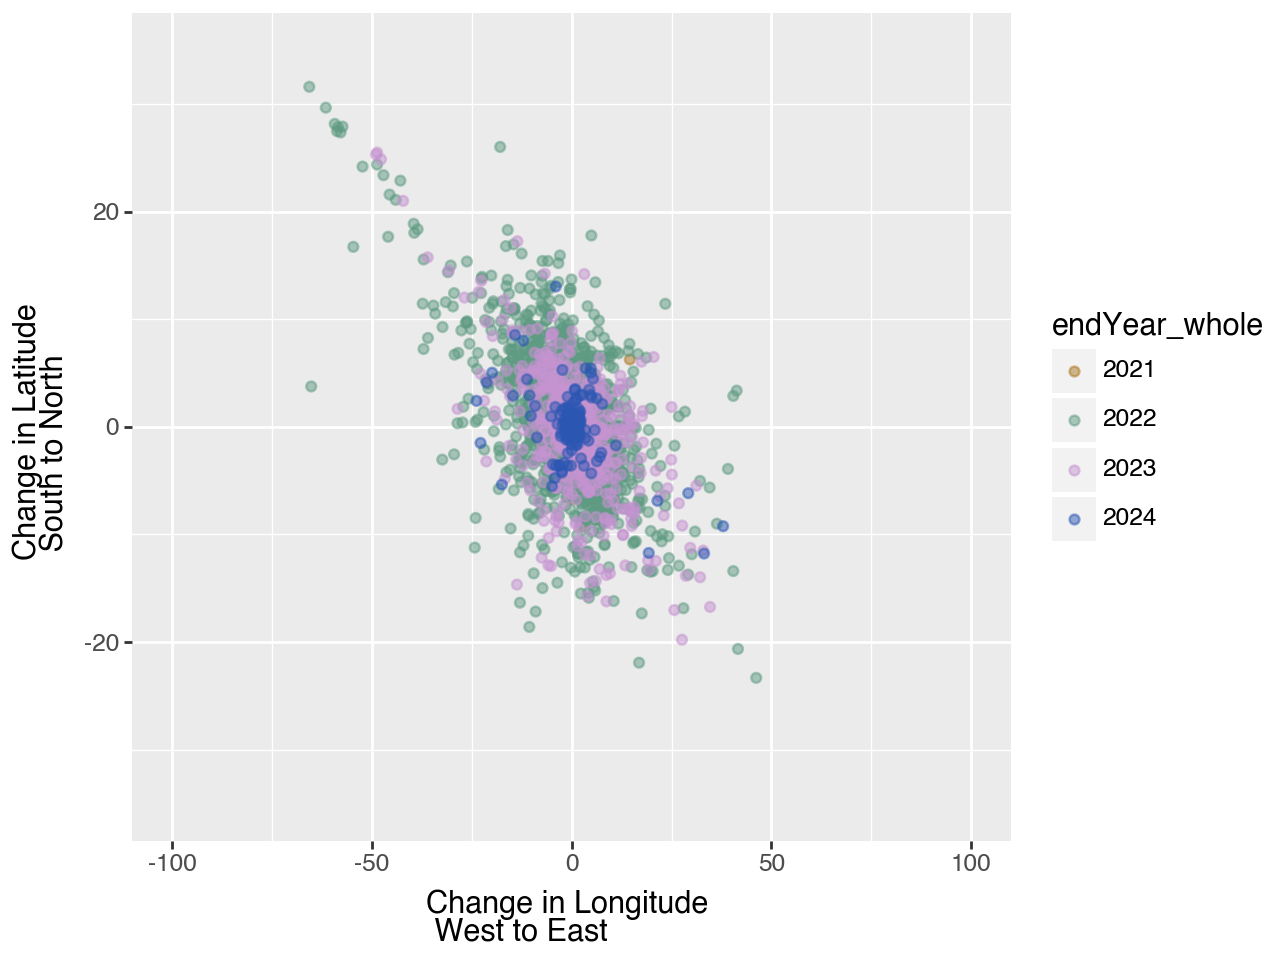

In [19]:
# Plot 1: change in direction of all points

year_colors = {"2021":"#AA7722",
               "2022":"#5E9B82",
               "2023":"#C593D1",
               "2024":"#2B57B3"
              }

all_time_scatter = (
    ggplot(mcc_seas_mon, aes(x = "changeLon", y = "changeLat", color = "endYear_whole")) 
    + geom_point(alpha = 0.5)
#    + stat_ellipse(type='t', level=0.95, linetype='dashed', size=1)
    + scale_color_manual(values=year_colors)
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
)

all_time_scatter.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


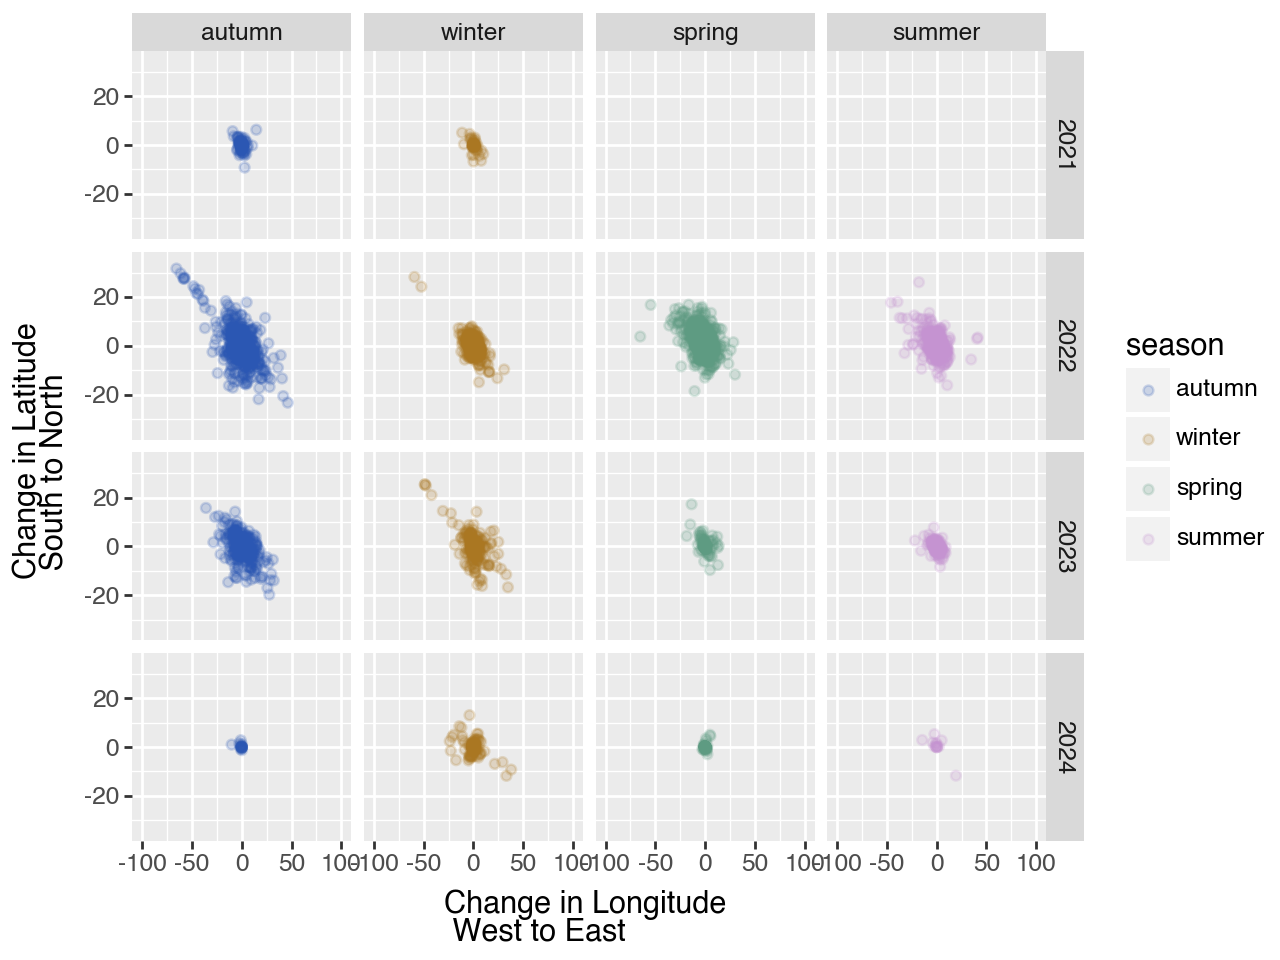

In [21]:
# Plot 1.5: change in direction, colored by season, facetted by year

season_colors = {"winter":"#AA7722",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#2B57B3"
              }

season_order = ["autumn", "winter", "spring", "summer"]
mcc_seas_mon["season"] = pd.Categorical(mcc_seas_mon["season"], categories=season_order, ordered=True)

seasonal_scatter = (
    ggplot(mcc_seas_mon, aes(x = "changeLon", y = "changeLat", color = "season")) 
    + geom_point(alpha = 0.2)
    # + stat_ellipse(type='t', level=0.95, size=1)
    + scale_color_manual(values=season_colors)
    # + facet_wrap("endYear_whole")
    + facet_grid("endYear_whole ~ season")
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
)

seasonal_scatter.show()

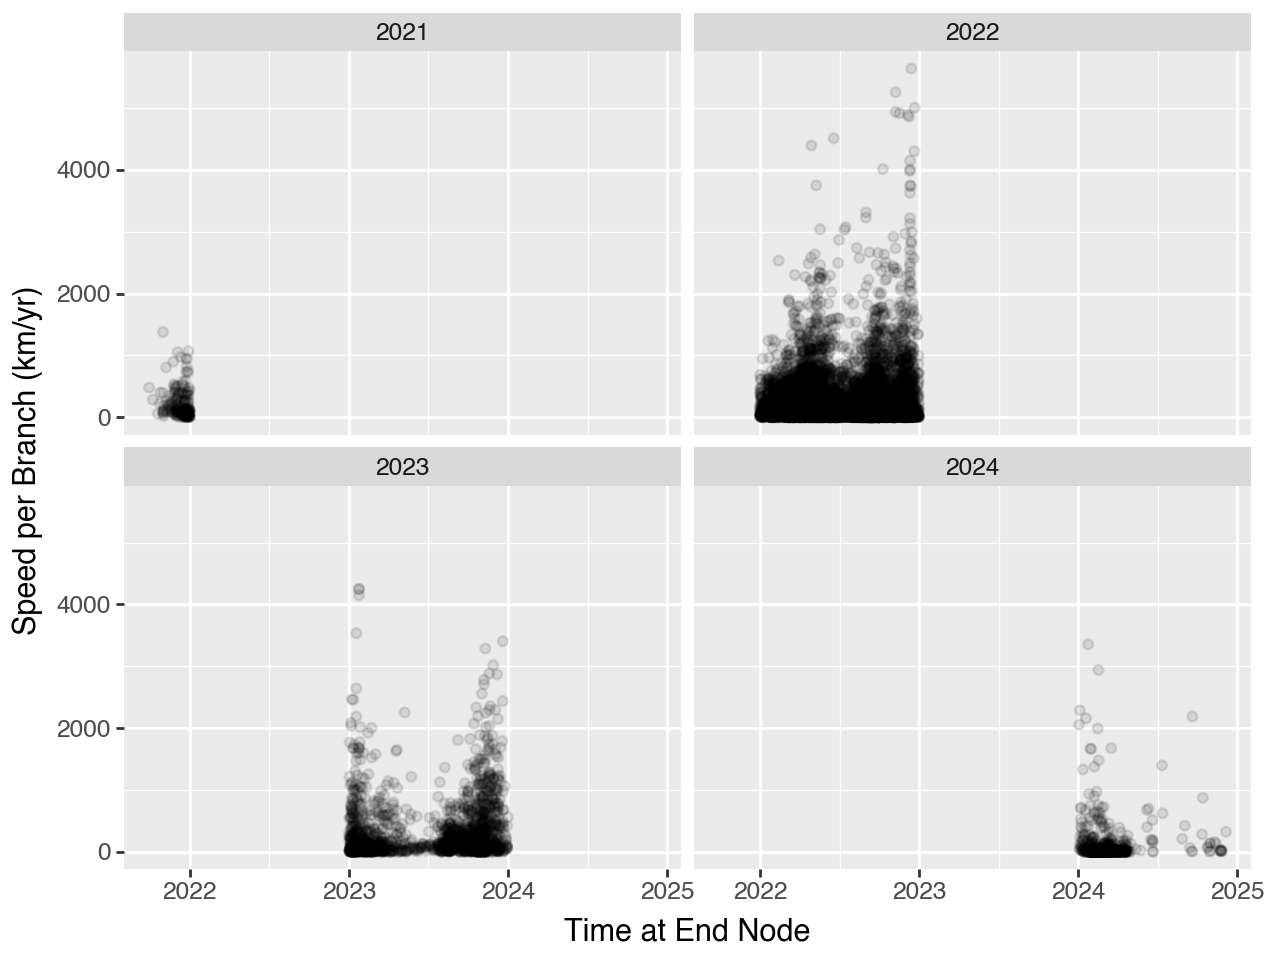

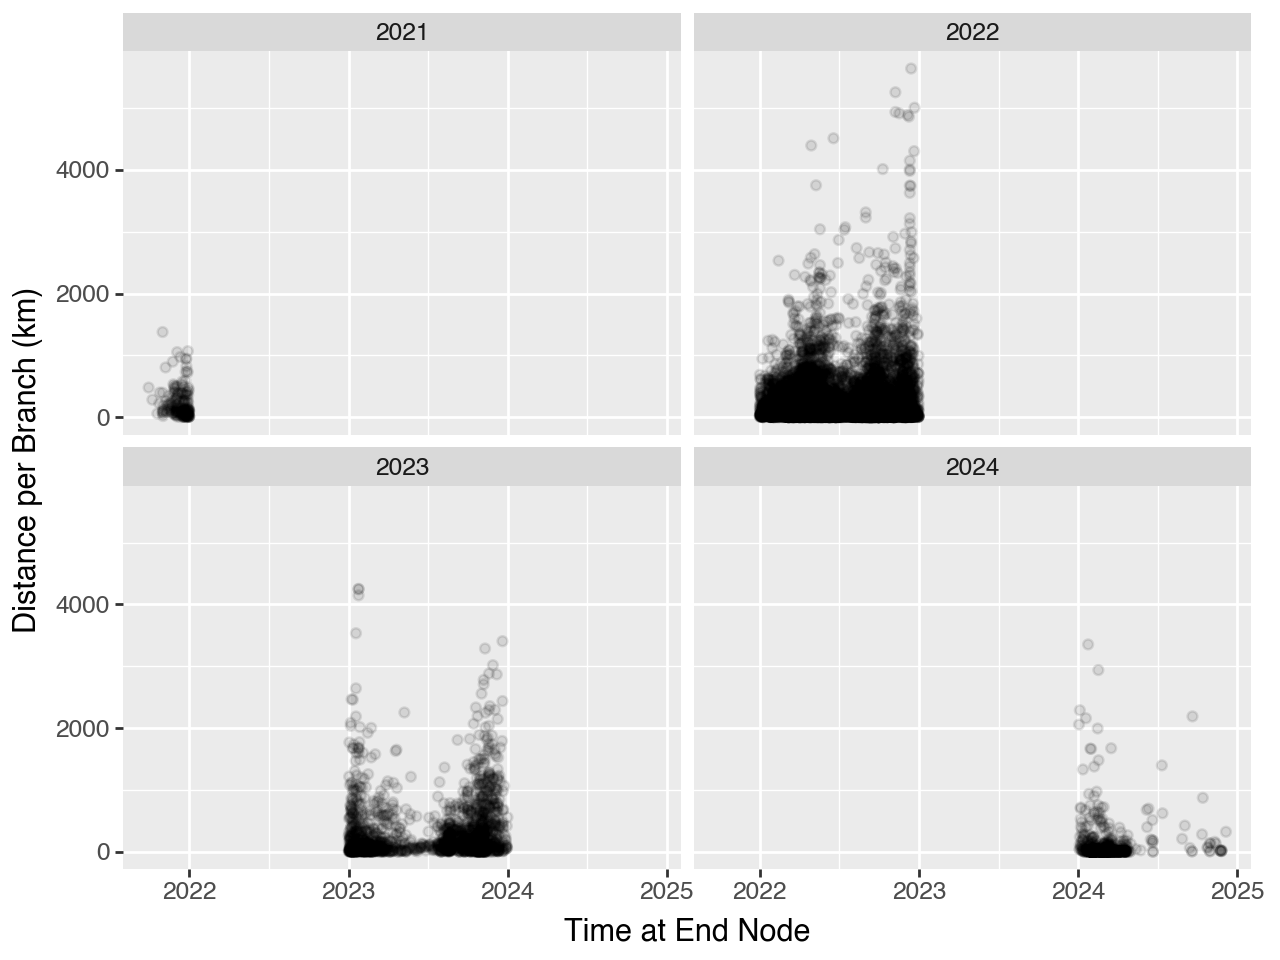

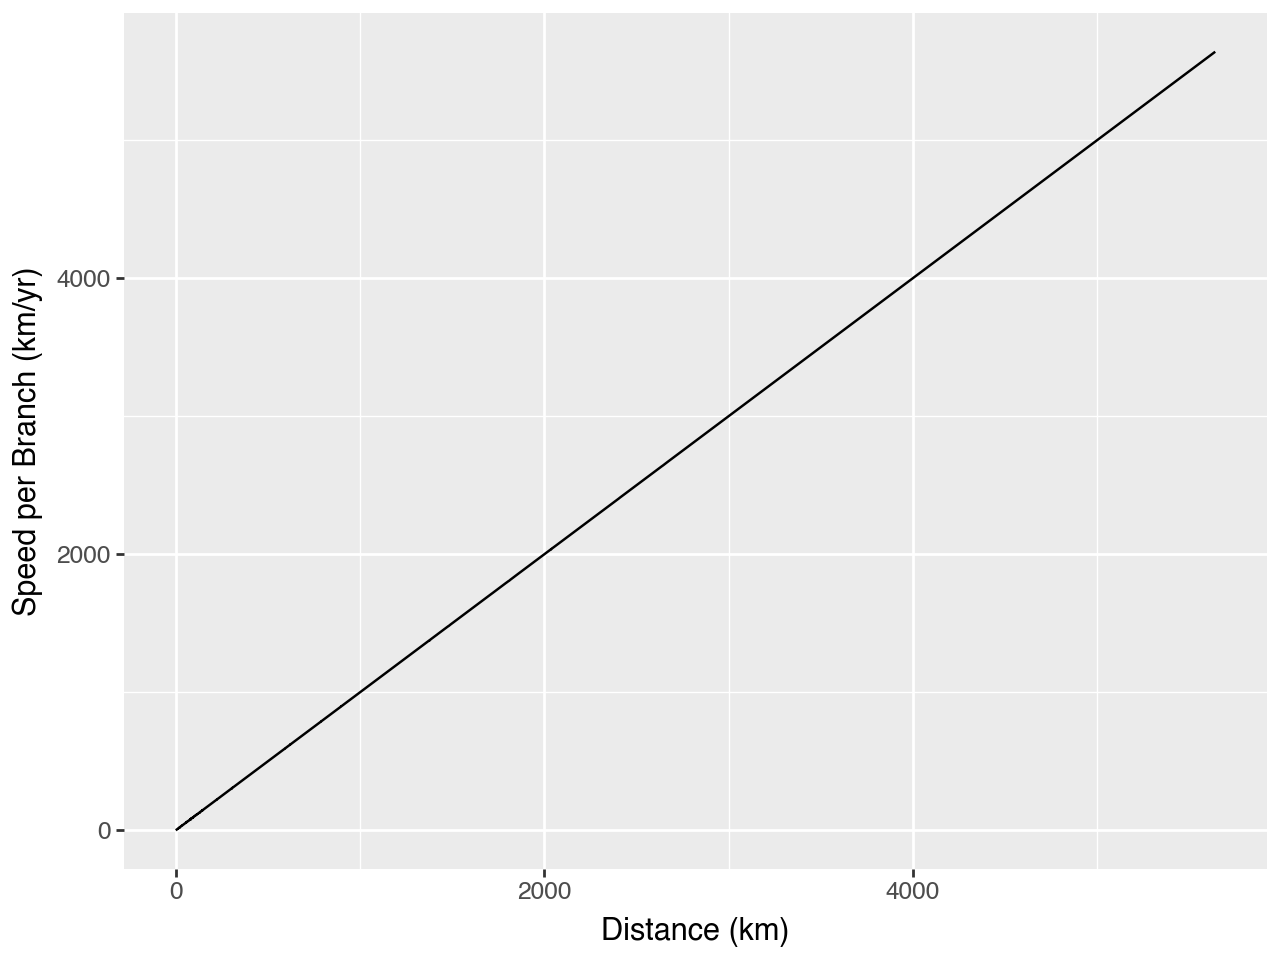

In [25]:
# Plots 2 and 3: speed and distance over time 

speed_over_time = (
    ggplot(mcc_seas_mon, aes(x = "endYear", y = "branchSpeed")) 
    + geom_point(alpha=0.1)
    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Speed per Branch (km/yr)")
)

dist_over_time = (
    ggplot(mcc_seas_mon, aes(x = "endYear", y = "dist_km")) 
    + geom_point(alpha=0.1)
    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Distance per Branch (km)")
)

dist_vs_speed = (
    ggplot(mcc_seas_mon, aes(x = "dist_km", y = "branchSpeed"))
    + geom_line()
    + labs(x = "Distance (km)", y = "Speed per Branch (km/yr)")
)

speed_over_time.show()
dist_over_time.show()
dist_vs_speed.show()

In [24]:
# Compute some statistics

In [22]:
# Statistics per year

stats_by_year_df = pd.DataFrame(["2021", "2022", "2023", "2024"]).rename({0:"year"}, axis = 1)

stats_by_year_df["total_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].sum().to_list()
stats_by_year_df["mean_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].mean().to_list()
stats_by_year_df["median_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].median().to_list()
stats_by_year_df["sd_speedperbranch"] = mcc_seas_mon.groupby('endYear_whole')['branchSpeed'].std().to_list()

stats_by_year_df.head()

,year,total_speedperbranch,mean_speedperbranch,median_speedperbranch,sd_speedperbranch
0,2021,3.908436e+04,222.070222,120.837233,245.211754
1,2022,2.310952e+06,246.422677,104.912816,405.661566
2,2023,5.751816e+05,337.349931,137.949823,499.923536
3,2024,7.451744e+04,97.408419,9.795179,301.899445


In [20]:
# Statistics per season

#mcc_seas_mon["season_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["season"].astype(str) # This is totally wrong
# If I make season_year this way, it considers December 2022 in the same season as January 2022, and they are NOT

stats_by_season_df = pd.DataFrame(["autumn", "winter", "spring", "summer"]).rename({0:"season"}, axis = 1)

stats_by_season_df["total_changeLat"] = mcc_seas_mon.groupby('season')['changeLat'].sum().to_list()
stats_by_season_df["avg_changeLat"] = mcc_seas_mon.groupby('season')['changeLat'].mean().to_list()
stats_by_season_df["total_changeLon"] = mcc_seas_mon.groupby('season')['changeLon'].sum().to_list()
stats_by_season_df["avg_changeLon"] = mcc_seas_mon.groupby('season')['changeLon'].mean().to_list()

print(stats_by_season_df) # Table view

   season  total_changeLat  avg_changeLat  total_changeLon  avg_changeLon
0  autumn      -343.139124      -0.117032         9.915012       0.003382
1  winter      1623.138467       0.427817     -1427.056163      -0.376135
2  spring       191.109756       0.079069      -807.137267      -0.333942
3  summer      -210.229821      -0.072971       209.012496       0.072549


In [29]:
# T test - Change in Latitude and Longitude

# First: make a list of the change in latitude and longitude by season
changeLat_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"]["changeLat"].to_list()
changeLat_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"]["changeLat"].to_list()
changeLat_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"]["changeLat"].to_list()
changeLat_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"]["changeLat"].to_list()

changeLon_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"]["changeLon"].to_list()
changeLon_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"]["changeLon"].to_list()
changeLon_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"]["changeLon"].to_list()
changeLon_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"]["changeLon"].to_list()

# Set up a dataframe
change_ttest = pd.DataFrame(["Autumn-Winter", "Autumn-Spring", "Autumn-Summer", 
                                "Winter-Spring", "Winter-Summer",
                                "Spring-Summer"]).rename({0:"Compared"}, axis = 1)

# Calculate t-statistics and p-values
t_statistic_lat_AutWin, p_value_lat_AutWin = ttest_ind(changeLat_autumn, changeLat_winter) # should check and make sure this is a commonly used function
t_statistic_lat_AutSpr, p_value_lat_AutSpr = ttest_ind(changeLat_autumn, changeLat_spring)
t_statistic_lat_AutSum, p_value_lat_AutSum = ttest_ind(changeLat_autumn, changeLat_summer)
t_statistic_lat_WinSpr, p_value_lat_WinSpr = ttest_ind(changeLat_winter, changeLat_spring)
t_statistic_lat_WinSum, p_value_lat_WinSum = ttest_ind(changeLat_winter, changeLat_summer)
t_statistic_lat_SprSum, p_value_lat_SprSum = ttest_ind(changeLat_spring, changeLat_summer)

t_statistic_lon_AutWin, p_value_lon_AutWin = ttest_ind(changeLon_autumn, changeLon_winter) 
t_statistic_lon_AutSpr, p_value_lon_AutSpr = ttest_ind(changeLon_autumn, changeLon_spring)
t_statistic_lon_AutSum, p_value_lon_AutSum = ttest_ind(changeLon_autumn, changeLon_summer)
t_statistic_lon_WinSpr, p_value_lon_WinSpr = ttest_ind(changeLon_winter, changeLon_spring)
t_statistic_lon_WinSum, p_value_lon_WinSum = ttest_ind(changeLon_winter, changeLon_summer)
t_statistic_lon_SprSum, p_value_lon_SprSum = ttest_ind(changeLon_spring, changeLon_summer)

# Add values to columns
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "T Statistic (Latitude)"] = t_statistic_lat_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "P Value (Latitude)"] = p_value_lat_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "T Statistic (Latitude)"] = t_statistic_lat_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "P Value (Latitude)"] = p_value_lat_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "T Statistic (Latitude)"] = t_statistic_lat_AutSum
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "P Value (Latitude)"] = p_value_lat_AutSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "T Statistic (Latitude)"] = t_statistic_lat_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "P Value (Latitude)"] = p_value_lat_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "T Statistic (Latitude)"] = t_statistic_lat_WinSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "P Value (Latitude)"] = p_value_lat_WinSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "T Statistic (Latitude)"] = t_statistic_lat_SprSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "P Value (Latitude)"] = p_value_lat_SprSum

change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "T Statistic (Longitude)"] = t_statistic_lon_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "P Value (Longitude)"] = p_value_lon_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "T Statistic (Longitude)"] = t_statistic_lon_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "P Value (Longitude)"] = p_value_lon_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "T Statistic (Longitude)"] = t_statistic_lon_AutSum
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "P Value (Longitude)"] = p_value_lon_AutSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "T Statistic (Longitude)"] = t_statistic_lon_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "P Value (Longitude)"] = p_value_lon_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "T Statistic (Longitude)"] = t_statistic_lon_WinSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "P Value (Longitude)"] = p_value_lon_WinSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "T Statistic (Longitude)"] = t_statistic_lon_SprSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "P Value (Longitude)"] = p_value_lon_SprSum

print(change_ttest)

        Compared  T Statistic (Latitude)  P Value (Latitude)  \
0  Autumn-Winter               -0.522229        6.015306e-01   
1  Autumn-Spring               -7.000575        2.796096e-12   
2  Autumn-Summer               -2.234039        2.552167e-02   
3  Winter-Spring               -8.309147        1.156884e-16   
4  Winter-Summer               -2.445153        1.451142e-02   
5  Spring-Summer                5.712669        1.163744e-08   

   T Statistic (Longitude)  P Value (Longitude)  
0                -0.470874             0.637748  
1                 2.360780             0.018265  
2                 2.193133             0.028341  
3                 3.263116             0.001107  
4                 3.640395             0.000275  
5                -0.291557             0.770635  


In [54]:
# T test - Average Latitude

avgLat_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"].groupby("endYear_whole")["changeLat"].mean().to_list()

avgLat_ttest = pd.DataFrame(["Autumn-Winter", "Autumn-Spring", "Autumn-Summer", 
                                "Winter-Spring", "Winter-Summer",
                                "Spring-Summer"]).rename({0:"Compared"}, axis = 1)

t_statistic_avgLat_AutWin, p_value_avgLat_AutWin = ttest_ind(avgLat_autumn, avgLat_winter) # should check and make sure this is a commonly used function
t_statistic_avgLat_AutSpr, p_value_avgLat_AutSpr = ttest_ind(avgLat_autumn, avgLat_spring)
t_statistic_avgLat_AutSum, p_value_avgLat_AutSum = ttest_ind(avgLat_autumn, avgLat_summer)
t_statistic_avgLat_WinSpr, p_value_avgLat_WinSpr = ttest_ind(avgLat_winter, avgLat_spring)
t_statistic_avgLat_WinSum, p_value_avgLat_WinSum = ttest_ind(avgLat_winter, avgLat_summer)
t_statistic_avgLat_SprSum, p_value_avgLat_SprSum = ttest_ind(avgLat_spring, avgLat_summer)

avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Winter", "T Statistic"] = t_statistic_avgLat_AutWin
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Winter", "P Value"] = p_value_avgLat_AutWin
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Spring", "T Statistic"] = t_statistic_avgLat_AutSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Spring", "P Value"] = p_value_avgLat_AutSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Summer", "T Statistic"] = t_statistic_avgLat_AutSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Summer", "P Value"] = p_value_avgLat_AutSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Spring", "T Statistic"] = t_statistic_avgLat_WinSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Spring", "P Value"] = p_value_avgLat_WinSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Summer", "T Statistic"] = t_statistic_avgLat_WinSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Summer", "P Value"] = p_value_avgLat_WinSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Spring-Summer", "T Statistic"] = t_statistic_avgLat_SprSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Spring-Summer", "P Value"] = p_value_avgLat_SprSum

print(avgLat_ttest)

        Compared  T Statistic   P Value
0  Autumn-Winter     0.756135  0.478194
1  Autumn-Spring    -1.912072  0.114083
2  Autumn-Summer    -0.935915  0.392282
3  Winter-Spring    -3.308645  0.021272
4  Winter-Summer    -2.068790  0.093383
5  Spring-Summer     0.947540  0.397018


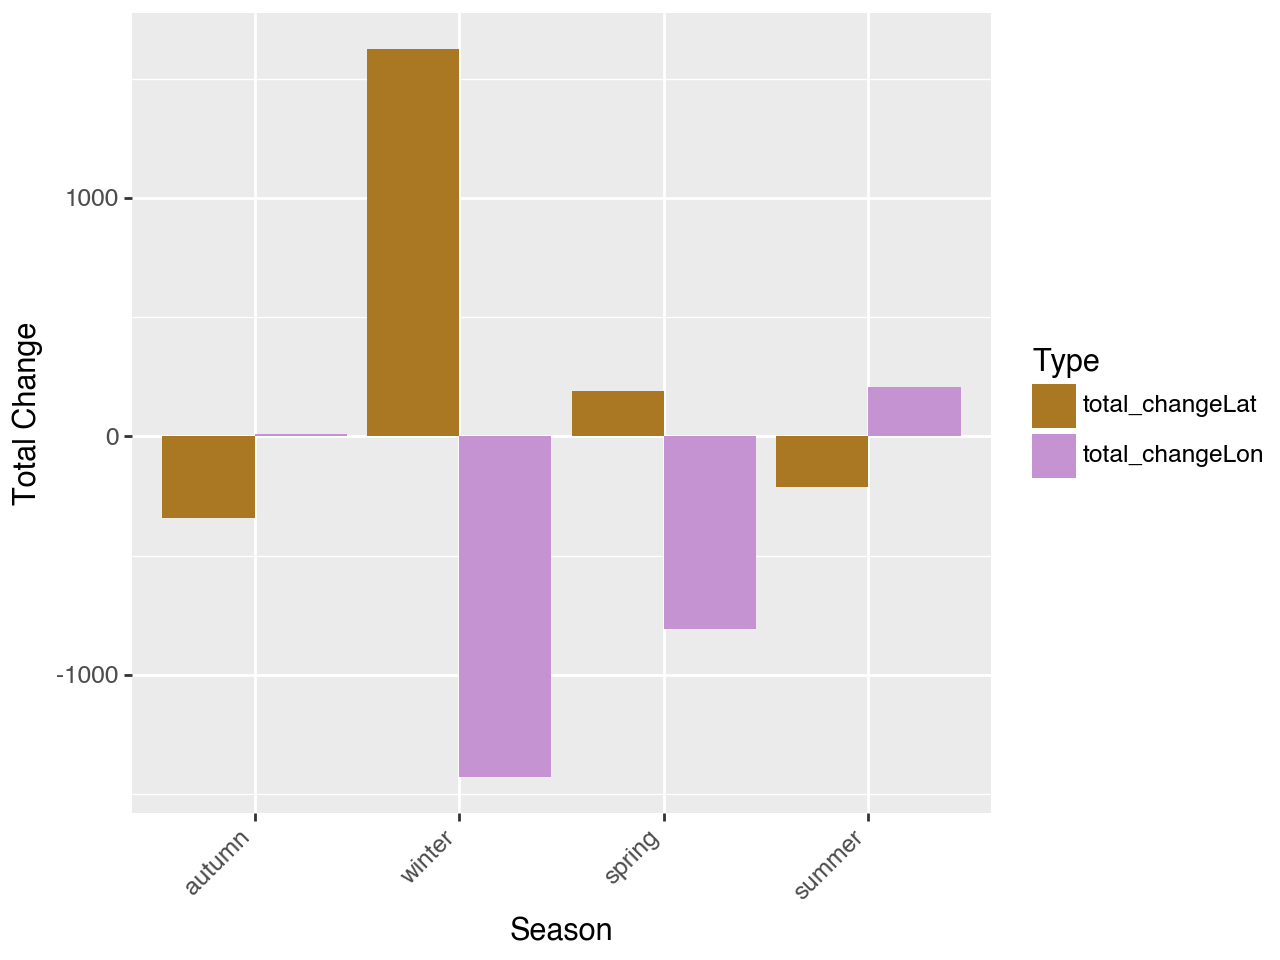

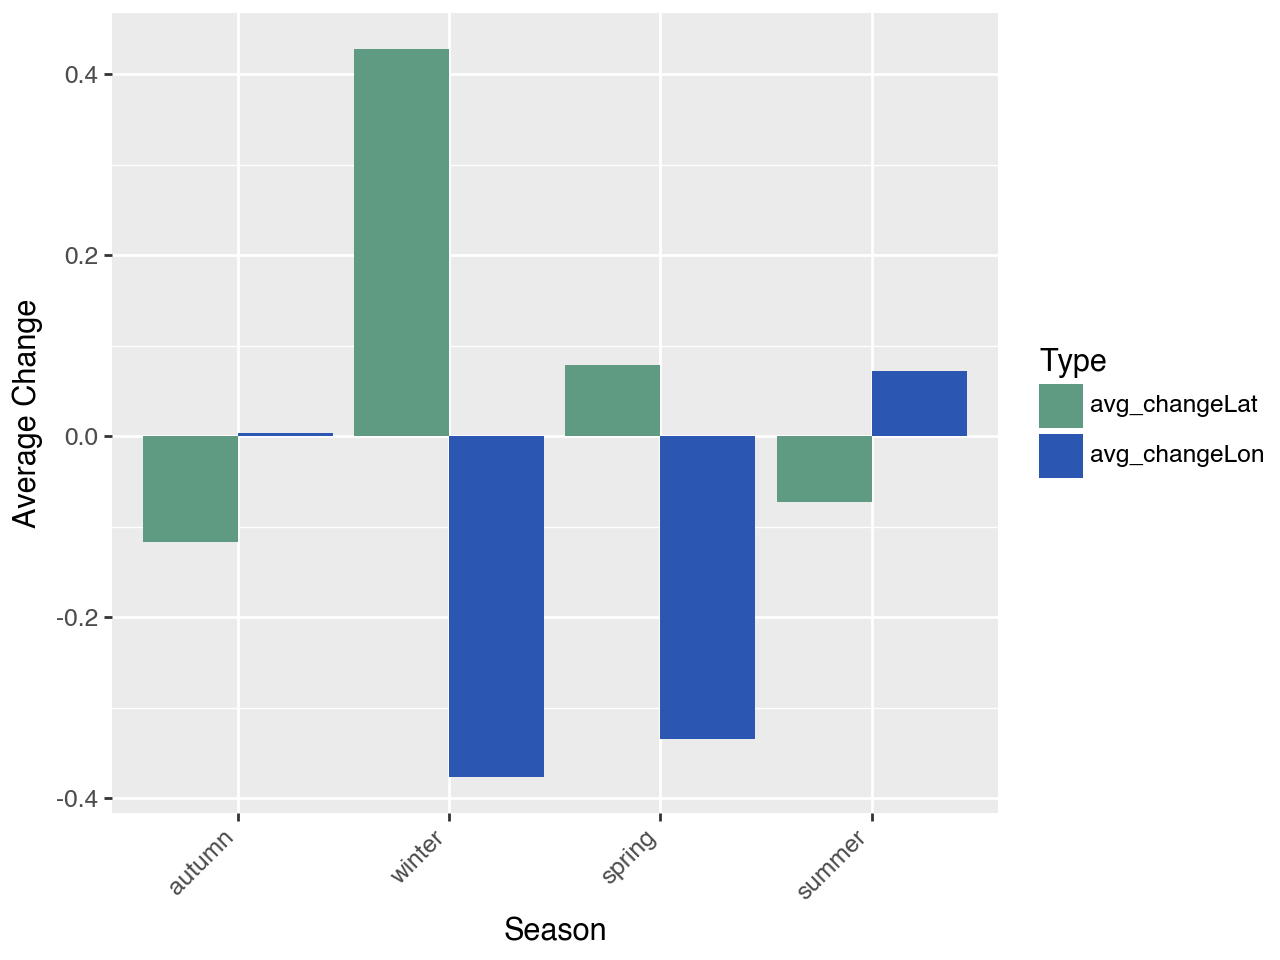

In [21]:
# Plot 4: change in lat and long per season

# Chat GPT says I need to reshape by df first
stats_by_season_long = stats_by_season_df.melt(
    id_vars=['season'], 
    value_vars=['total_changeLat', 'avg_changeLat', 'total_changeLon', 'avg_changeLon'],
    var_name='change_type',
    value_name='value'
)

season_order = ["autumn", "winter", "spring", "summer"]
stats_by_season_long["season"] = pd.Categorical(stats_by_season_long["season"], categories=season_order, ordered=True)

# Filter for averages
filtered_total = stats_by_season_long[stats_by_season_long["change_type"].isin(["total_changeLat", "total_changeLon"])]

# Filter for totals
filtered_avg = stats_by_season_long[stats_by_season_long["change_type"].isin(["avg_changeLat", "avg_changeLon"])]

total_change_per_season = (
    ggplot(filtered_total) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Total Change", fill = "Type")
    + scale_fill_manual(values={'total_changeLat': '#AA7722','total_changeLon': '#C593D1'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

avg_change_per_season = (
    ggplot(filtered_avg) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Average Change", fill = "Type")
    + scale_fill_manual(values={'avg_changeLat': '#5E9B82', 'avg_changeLon': '#2B57B3'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

total_change_per_season.show()
avg_change_per_season.show()

In [44]:
# Statistics per month_year

mcc_seas_mon["month_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["month"].astype(str)

stats_by_month_df = pd.DataFrame(["2021_september", "2021_october","2021_november","2021_december",
                                  "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
                                  "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december",
                                  "2023_january", "2023_february", "2023_march", "2023_april", "2023_may", "2023_june",
                                  "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december",
                                  "2024_january", "2024_february", "2024_march", "2024_april", "2024_may", "2024_june",
                                  "2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]).rename({0:"month"}, axis = 1)

stats_by_month_df["avg_startLat"] = mcc_seas_mon.groupby('month_year')['startLat'].mean().to_list()
stats_by_month_df["avg_startLon"] = mcc_seas_mon.groupby('month_year')['startLon'].mean().to_list()
stats_by_month_df["avg_endLat"] = mcc_seas_mon.groupby('month_year')['endLat'].mean().to_list()
stats_by_month_df["avg_endLon"] = mcc_seas_mon.groupby('month_year')['endLon'].mean().to_list()

#print(stats_by_month_df) # Table view

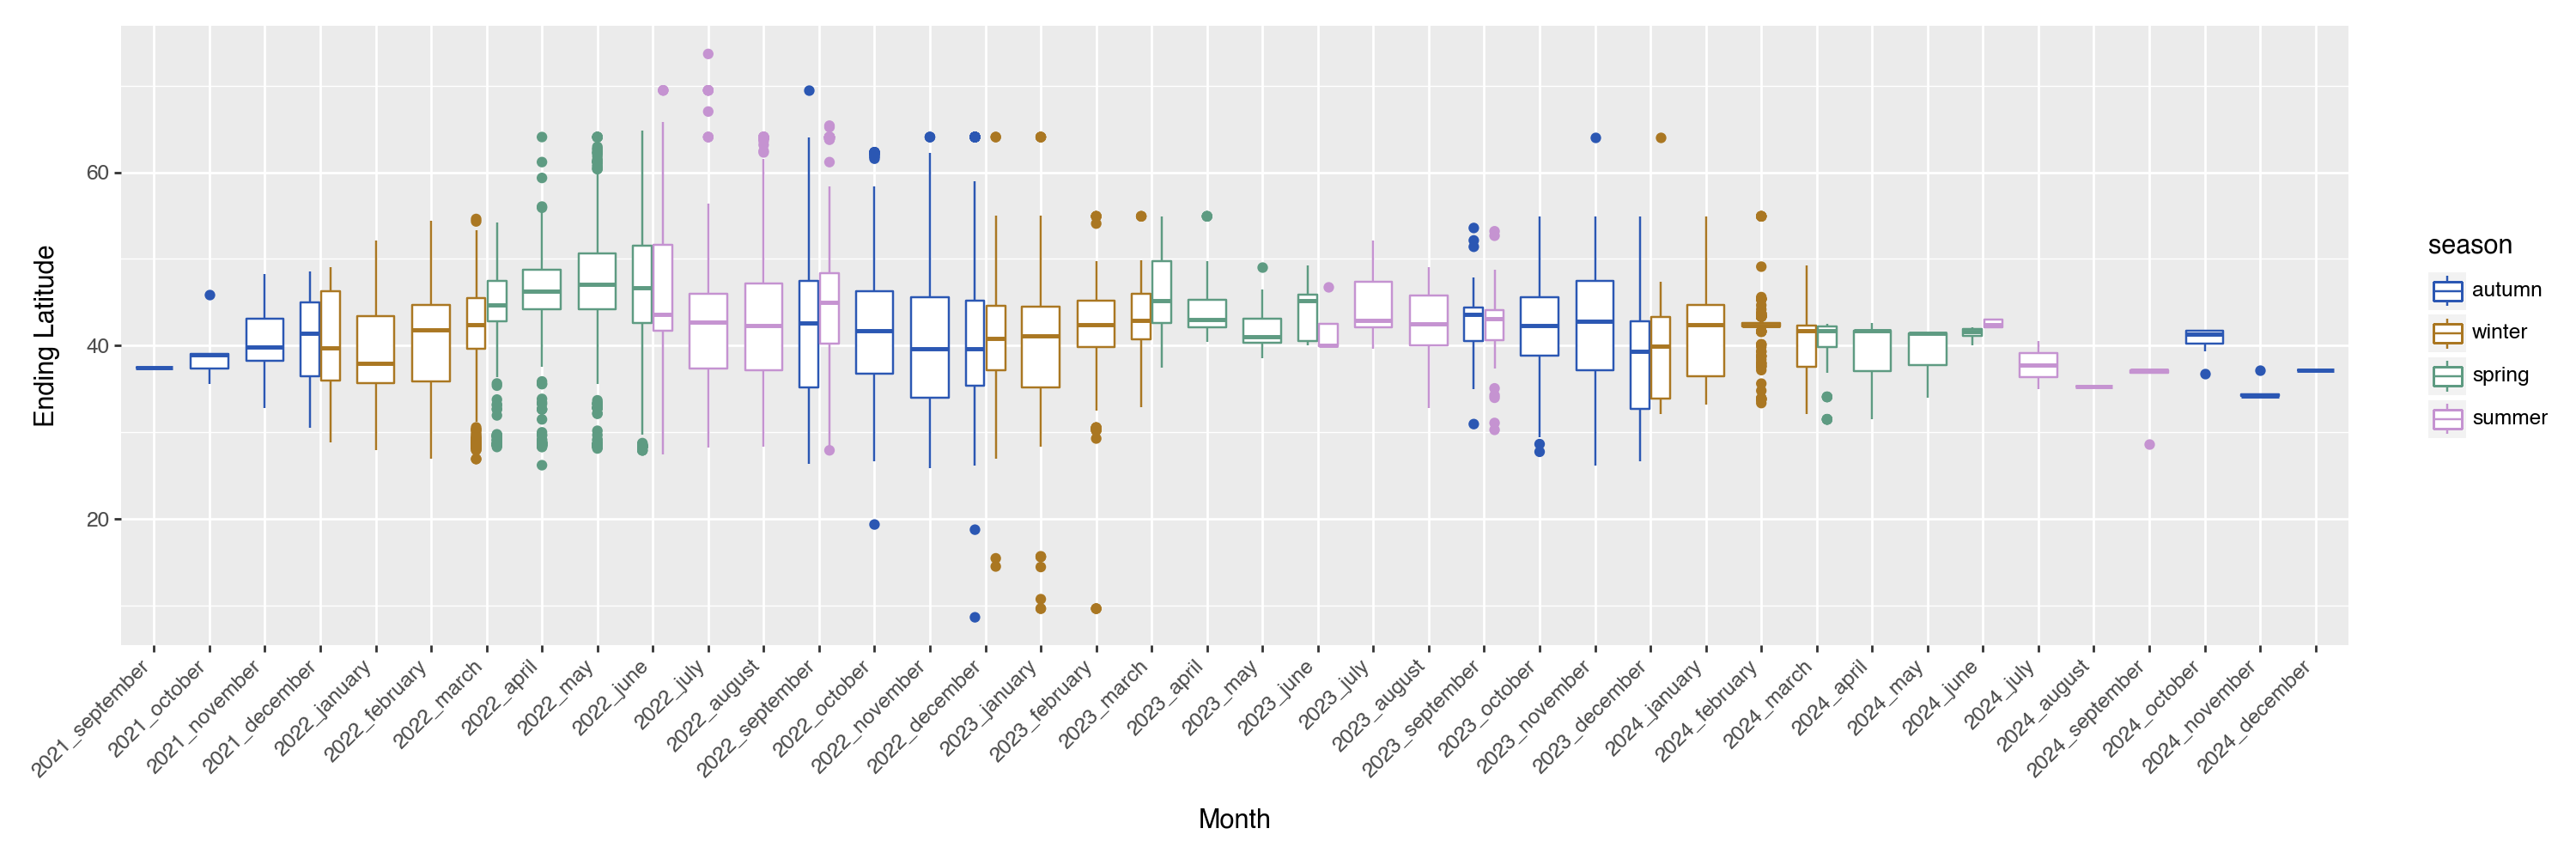

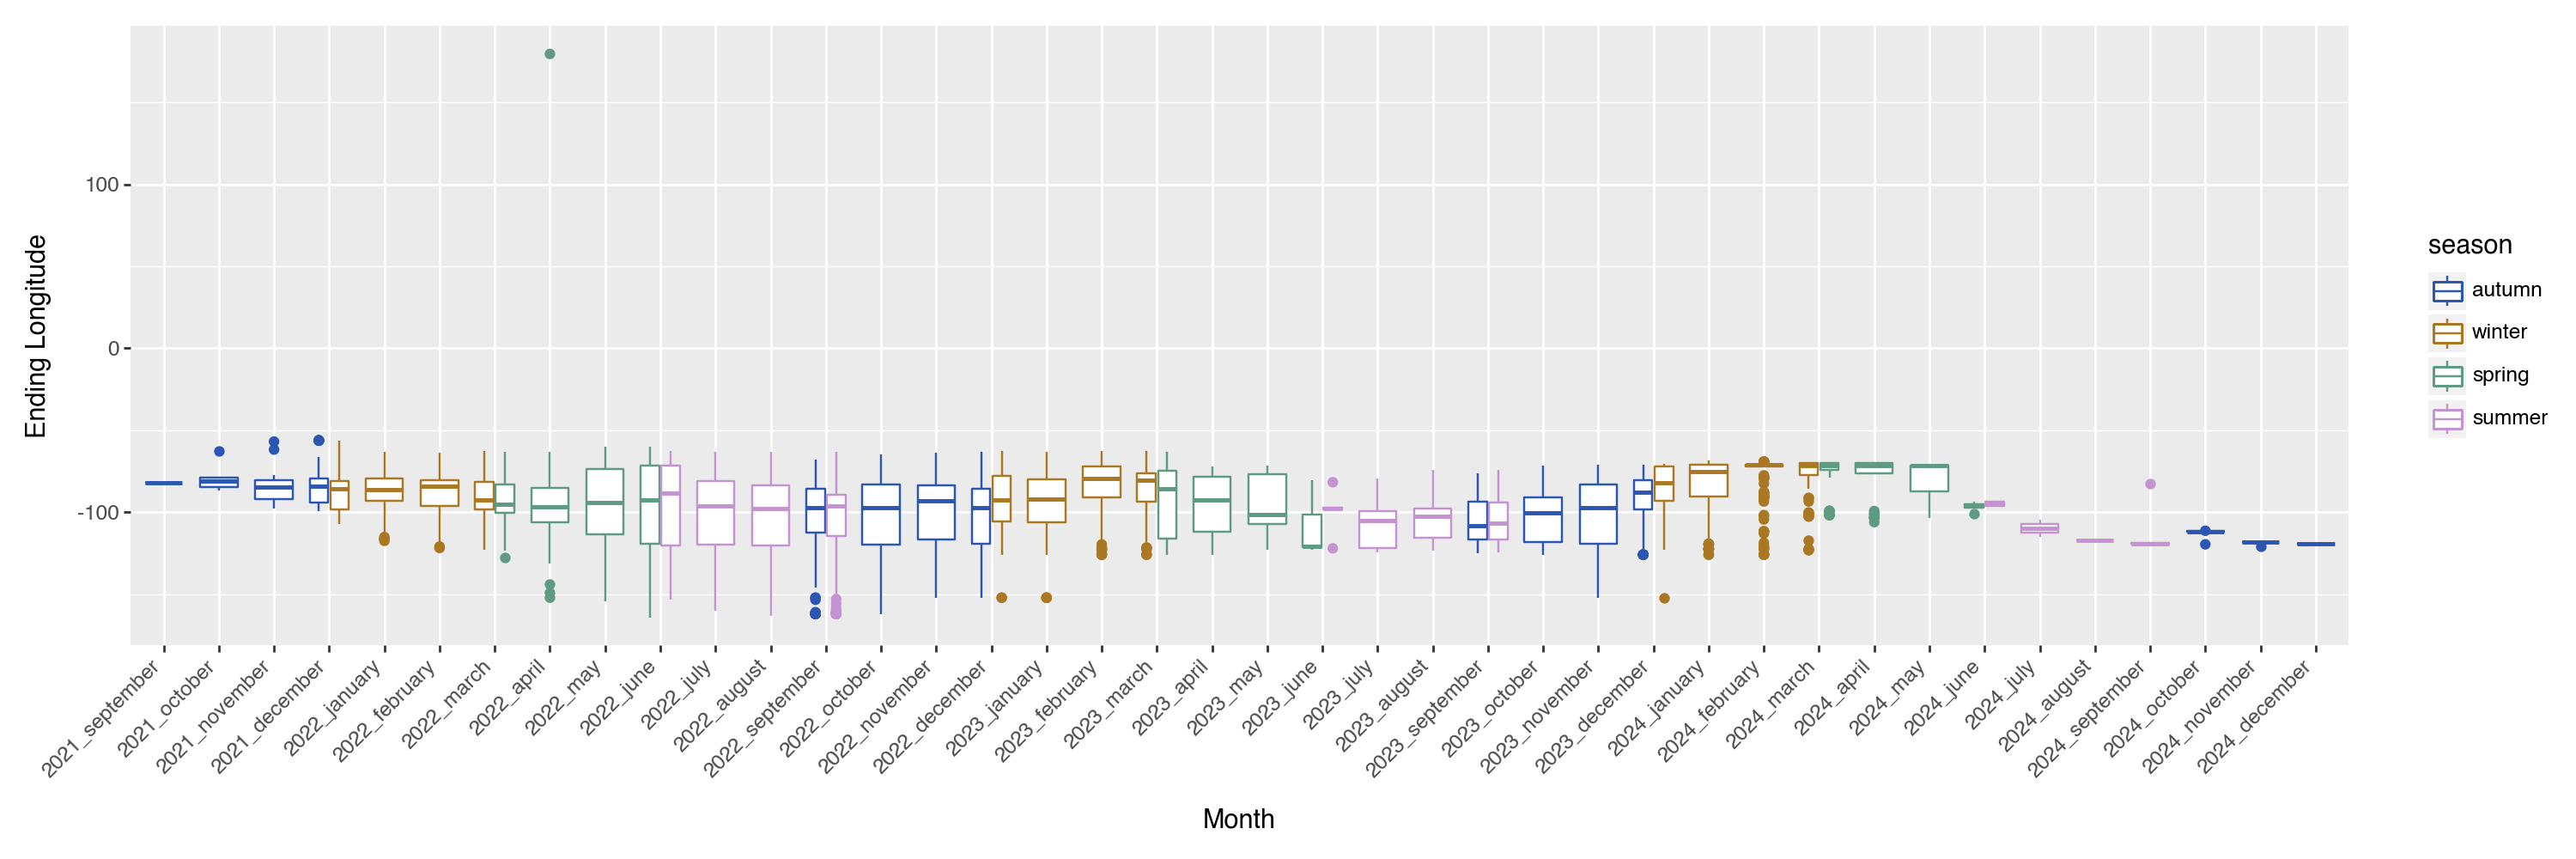

In [59]:
# Plot 5: average lat and lon per month

mcc_seas_mon["month_year"] = mcc_seas_mon["month_year"].astype(str)

month_order = ["2021_september", "2021_october","2021_november","2021_december", "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
               "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december","2023_january", "2023_february", "2023_march", "2023_april", 
               "2023_may", "2023_june", "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december", "2024_january", "2024_february", 
               "2024_march", "2024_april", "2024_may", "2024_june","2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]

mcc_seas_mon["month_year"] = pd.Categorical(mcc_seas_mon["month_year"], categories=month_order, ordered=True)

avg_latitude = (
    ggplot(mcc_seas_mon)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLat", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLat", color = "season"))
    + labs(x = "Month", y = "Ending Latitude")
    + scale_color_manual(values = season_colors)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)


avg_longitude = (
    ggplot(mcc_seas_mon)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLon", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLon", color = "season"))
    + labs(x = "Month", y = "Ending Longitude")
    + scale_color_manual(values = season_colors)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)

avg_latitude.show()
avg_longitude.show()

In [28]:
# Match lat/long to a flyway

In [19]:
# Anna's FIPS code assignment function

# def get_block_group_fips(lat, lon):
#     url = f"https://geo.fcc.gov/api/census/block/find?latitude={lat}&longitude={lon}&censusYear=2010&format=json"
#     response = requests.get(url)
#     data = response.json()
#     block_fips = data['Block']['FIPS']
#     block_group_fips = block_fips[:12]  # Truncate to 12 digits
#     return block_group_fips

# # Example
# print(get_block_group_fips(40.7128, -74.0060))  # Should return 12-digit FIPS

In [20]:
# First try by Clara

# from geopy.geocoders import Nominatim

# geolocator = Nominatim(user_agent="cm_plotting_app")

# def state(df, column1, column2):
#     coords = str((df[column1], df[column2]))
#     location = geolocator.reverse(coords)
#     state = location.raw["address"].get("state")
#     return state

In [21]:
# Second try by Chat GPT - too slow!

# Set up geolocator globally
# geolocator = Nominatim(user_agent="geo_lookup_app")

# def reverse_geocode(lat, lon):
#     try:
#         location = geolocator.reverse((lat, lon), language='en')
#         if location and 'state' in location.raw['address']:
#             return location.raw['address']['state']
#         else:
#             return None
#     except GeocoderTimedOut:
#         time.sleep(1)
#         return reverse_geocode(lat, lon)  # Retry once
#     except Exception as e:
#         print(f"Error for ({lat}, {lon}): {e}")
#         return None

# def add_state_column(df, lat_col, lon_col):
#     df["state"] = df.apply(lambda row: reverse_geocode(row[lat_col], row[lon_col]), axis=1)
#     return df

In [22]:
#mcc_seasons["startState"] = add_state_column(mcc_seasons, "startLat", "startLon")

In [23]:
# Need a shapefile to dictate polygon boundaries

# North America shapefile
NAm_shp_path = "./metadata/shapefiles/north_america/north_america.shp"
NAm_gdf = gpd.read_file(NAm_shp_path)

# Downloaded US shapefile from Natural Earth
# Downloaded Canadian province shapefile from: https://open.canada.ca/data/en/dataset/a883eb14-0c0e-45c4-b8c4-b54c4a819edb/resource/12c03de6-c3f7-4f5f-bb5c-d479f2332842
# Downloaded Mexican state shapefile from: https://github.com/jschleuss/mexican-states

In [24]:
# Filter for U.S. states and desired countries

# # Filter for US States
# us_states = states_gdf[states_gdf['admin'] == 'United States of America']

# # List of countries to include
# country_list = ["Canada", "Mexico"]

# selected_countries = countries_gdf[countries_gdf['ADMIN'].isin(country_list)]

In [25]:
# Reproject, just in case
# selected_countries = selected_countries.to_crs("EPSG:4326")

# # Combine both GeoDataFrames
# combined_gdf = pd.concat([us_states, selected_countries], ignore_index=True)

In [26]:
# I would like to see what is happening in my shapefile DF

NAm_gdf["geometry_name"] = NAm_gdf["name"].combine_first(NAm_gdf["PRNAME"])
columns = ["geometry", "geometry_name", "place", "type", "latitude", "longitude", "fips", "region", "gadm_level"]
NAm_gdf = NAm_gdf.loc[0:, columns]

NAm_gdf = NAm_gdf.to_crs("EPSG:4326")

In [27]:
# Create geometries for each start and end point in the MCC tree

mcc_seas_mon['startGeometry'] = mcc_seas_mon.apply(lambda row: Point(row['startLon'], row['startLat']), axis=1)
mcc_seas_mon['endGeometry'] = mcc_seas_mon.apply(lambda row: Point(row['endLon'], row['endLat']), axis=1)

geop_mcc_seas_mon_start = gpd.GeoDataFrame(mcc_seas_mon, geometry='startGeometry', crs="EPSG:4326")
geop_mcc_seas_mon_end = gpd.GeoDataFrame(mcc_seas_mon, geometry='endGeometry', crs="EPSG:4326")

geop_mcc_seas_mon_start = geop_mcc_seas_mon_start.set_crs("EPSG:4326", allow_override=True)
geop_mcc_seas_mon_end = geop_mcc_seas_mon_end.set_crs("EPSG:4326", allow_override=True)
# print(geop_mcc_seas_mon["startGeometry"])

# print(geop_mcc_seas_mon)

In [28]:
# Function: use gpd.sjoin to assign coordinates to the state (made by Chat GPT)

def assign_state(df, geom_col, states_gdf, new_col):
    temp = df.set_geometry(geom_col, inplace=False)

    # # CRS check and force match
    # if temp.crs != states_gdf.crs:
    #     temp = temp.to_crs(states_gdf.crs)

    result = gpd.sjoin(temp, states_gdf[["geometry_name", "geometry"]], how="left", predicate="within")
    state_series = result.rename(columns={"geometry_name": new_col})[new_col]
    return state_series.reindex(df.index)

In [29]:
mcc_seas_mon["startState"] = assign_state(geop_mcc_seas_mon_start, "startGeometry", NAm_gdf, "startState")
mcc_seas_mon["endState"] = assign_state(geop_mcc_seas_mon_end, "endGeometry", NAm_gdf, "endState")

In [30]:
# Fix state/province names

# No French! (also some Mexico changes)
no_french_dict = {"Newfoundland and Labrador / Terre-Neuve-et-Labrador":"Newfoundland",
                 "Prince Edward Island / Île-du-Prince-Édouard":"Prince Edward Island",
                 "British Columbia / Colombie-Britannique":"British Columbia",
                 "Northwest Territories / Territoires du Nord-Ouest":"Northwest Territories",
                 "Quebec / Québec":"Quebec",
                 "Nova Scotia / Nouvelle-Écosse":"Nova Scotia",
                 "New Brunswick / Nouveau-Brunswick":"New Brunswick",
                 "Coahuila de Zaragoza":"Coahuila",
                 "Veracruz de Ignacio de la Llave":"Veracruz",
                 "Michoacán de Ocampo":"Michoacán"
                 }

# Make the above adjustmane
mcc_seas_mon["startState"] = mcc_seas_mon["startState"].map(no_french_dict).fillna(mcc_seas_mon["startState"]) # what does this fill NA with?
mcc_seas_mon["endState"] = mcc_seas_mon["endState"].map(no_french_dict).fillna(mcc_seas_mon["endState"])

In [31]:
# Function: Standardize state names

def fix_state_name(name):
    if pd.isna(name):
        return name
    replacements = {"é": "e", "á": "a", "í": "i", "ó": "o"}
    name = name.lower()
    name = name.replace("-", "").replace(" ", "").replace("'", "")
    for accented, plain in replacements.items():
        name = name.replace(accented, plain)
    return name

In [32]:
# Standardize the states in both startState and endState

mcc_seas_mon_v2 = mcc_seas_mon.copy()

mcc_seas_mon_v2["startState"] = mcc_seas_mon_v2["startState"].apply(fix_state_name)
mcc_seas_mon_v2["endState"] = mcc_seas_mon_v2["endState"].apply(fix_state_name)

In [33]:
# Upload the state and flyway and turn it into a dictionary

# Upload the CSV of the state and flyway
state_flyway_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

state_flyway_df = pd.read_csv(state_flyway_csv, sep = ',') 

# Turn this CSV into a dictionary
state_flyway_dict = state_flyway_df.set_index("location").to_dict(orient="index")

In [34]:
# Add flyway

mcc_seas_mon_flyways = mcc_seas_mon_v2.copy()

mcc_seas_mon_flyways["startFlyway"] = mcc_seas_mon_flyways["startState"].map(lambda state: state_flyway_dict.get(state, {}).get("flyway"))
mcc_seas_mon_flyways["endFlyway"] = mcc_seas_mon_flyways["endState"].map(lambda state: state_flyway_dict.get(state, {}).get("flyway"))

In [35]:
mcc_seas_mon_flyways.head()

,node1,node2,length,startLon,startLat,endLon,endLat,endNodeL,startNodeL,startYear,...,month,dist_km,changeYear,branchSpeed,startGeometry,endGeometry,startState,endState,startFlyway,endFlyway
0,6014,6015,0.134134,-77.192847,39.606088,-81.985138,37.488593,0.134134,0.000000,2021.609902,...,september,479.256583,0.134134,479.122449,POINT (-77.1928469762194 39.6060875436214),POINT (-81.9851378125235 37.4885929790095),maryland,virginia,AtlanticFlyway,AtlanticFlyway
1,6015,9034,0.023139,-81.985138,37.488593,-84.675856,38.896095,0.157272,0.134134,2021.744036,...,october,282.768108,0.023139,282.744969,POINT (-81.9851378125235 37.4885929790095),POINT (-84.6758557078282 38.8960948578632),virginia,kentucky,AtlanticFlyway,MississippiFlyway
2,9034,9035,0.031183,-84.675856,38.896095,-84.255735,38.488669,0.188455,0.157272,2021.767175,...,october,58.150793,0.031183,58.119610,POINT (-84.6758557078282 38.8960948578632),POINT (-84.2557354887159 38.4886689209951),kentucky,kentucky,MississippiFlyway,MississippiFlyway
3,9035,9141,0.012011,-84.255735,38.488669,-86.741516,38.975548,0.200467,0.188455,2021.798358,...,october,222.790755,0.012011,222.778744,POINT (-84.2557354887159 38.4886689209951),POINT (-86.7415158654387 38.9755478006356),kentucky,indiana,MississippiFlyway,MississippiFlyway
4,9035,9036,0.015212,-84.255735,38.488669,-80.850620,36.146270,0.203668,0.188455,2021.798358,...,october,398.296537,0.015212,398.281324,POINT (-84.2557354887159 38.4886689209951),POINT (-80.8506195617789 36.1462704724088),kentucky,northcarolina,MississippiFlyway,AtlanticFlyway


In [33]:
# I wanted to check if either column has "unknown" values

print(mcc_seas_mon_flyways["startFlyway"].value_counts())
print(mcc_seas_mon_flyways["endFlyway"].value_counts())

# Both do have unknowns, probably because those coordinates are in the ocean

startFlyway
AtlanticFlyway       3338
CentralFlyway        3134
MississippiFlyway    2806
PacificFlyway        2128
unknown               618
Name: count, dtype: int64
endFlyway
AtlanticFlyway       3602
MississippiFlyway    2884
CentralFlyway        2843
PacificFlyway        2304
unknown               390
Name: count, dtype: int64


In [64]:
# Create a DataFrame of lat/lon from the geometries
def geom_to_df(geom, region_name):
#     if isinstance(geom, Polygon):
#         coords = list(geom.exterior.coords)
#         df = pd.DataFrame(coords, columns=['lon', 'lat'])
#         df['region'] = region_name
#         df['group'] = f"{region_name}_0"
#         return df

#     elif isinstance(geom, MultiPolygon):
#         dfs = []
#         for i, part in enumerate(geom.geoms):
#             coords = list(part.exterior.coords)
#             df = pd.DataFrame(coords, columns=['lon', 'lat'])
#             df['region'] = region_name
#             df['group'] = f"{region_name}_{i}"
#             dfs.append(df)
#             # Add NaN to separate parts (important for line-based plotting)
            # dfs.append(pd.DataFrame({
            #     'lon': [np.nan],
            #     'lat': [np.nan],
            #     'region': [region_name],
            #     'group': [f"{region_name}_{i}"]
            # }))
#         return pd.concat(dfs, ignore_index=True)

    if isinstance(geom, LineString):
        coords = list(geom.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiLineString):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
#            dfs.append(pd.DataFrame({'lon': [np.nan],'lat': [np.nan],'region': [region_name],'group': [f"{region_name}_{i}"]}))
        return pd.concat(dfs, ignore_index=True)

    else:
        return pd.DataFrame(columns=['lon', 'lat', 'region', 'group'])

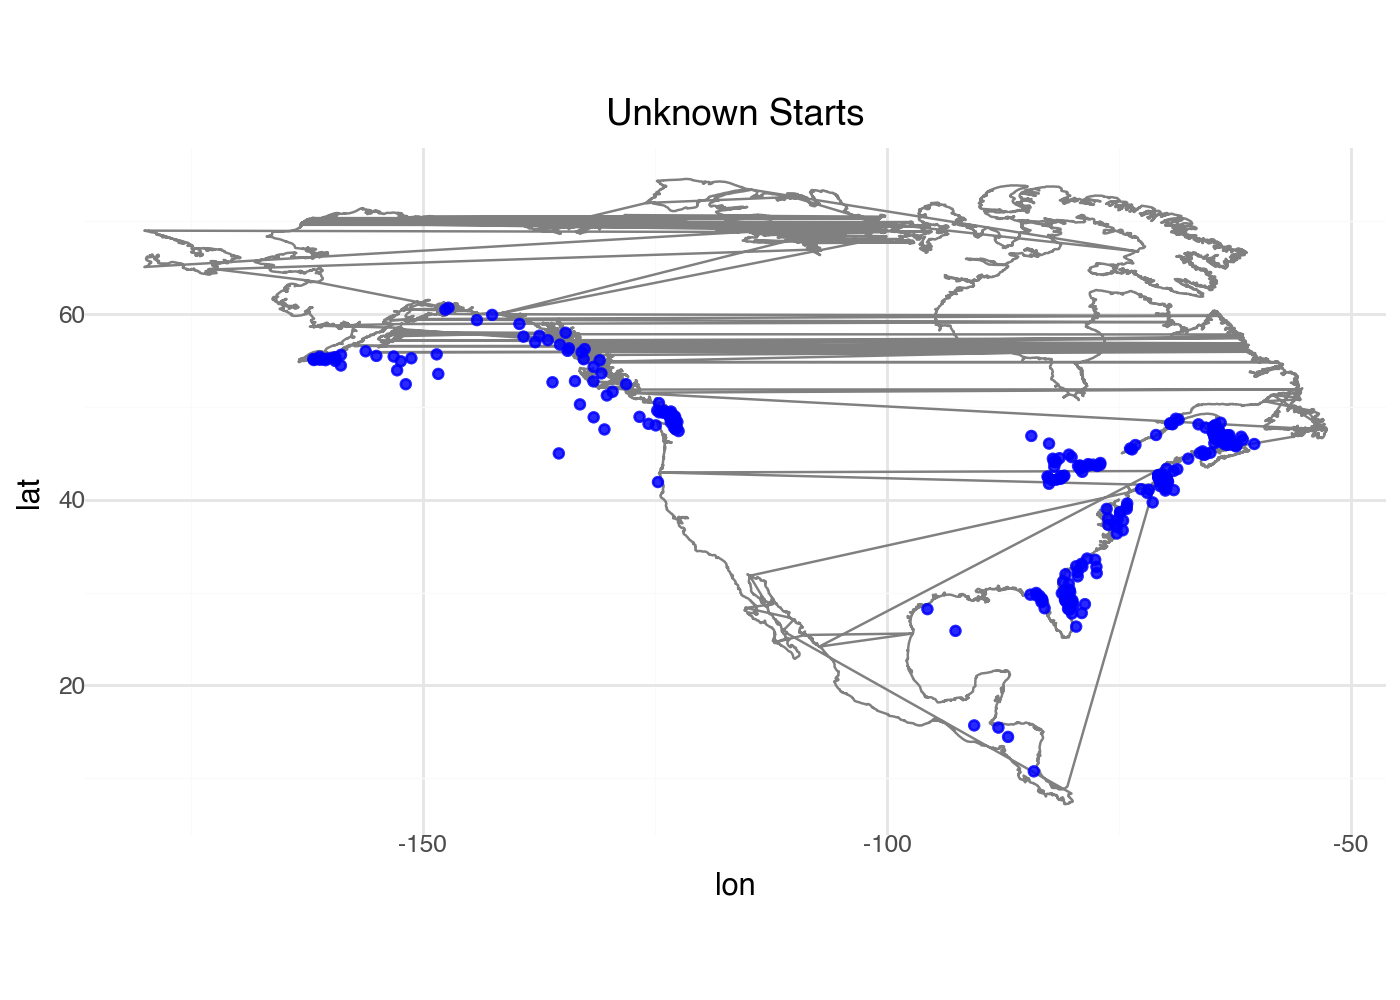

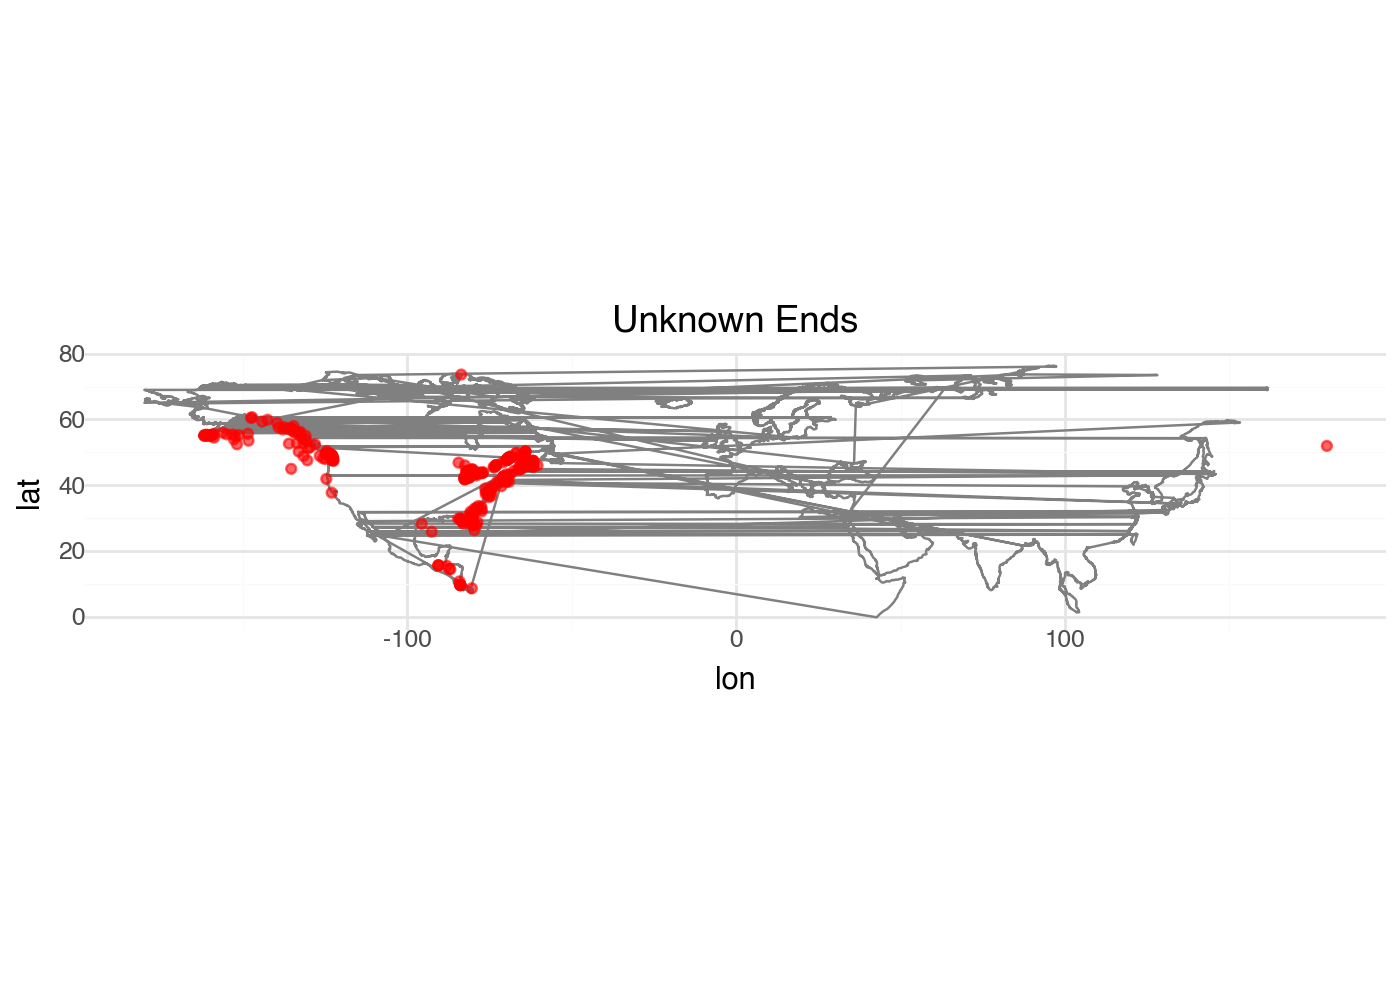

In [85]:
# I suspect all the unknowns are either in the Atlantic or Pacific Ocean, but I will need to be sure

# subset dataframe to just those with unknown start flyway
unknown_starts = mcc_seas_mon_flyways[mcc_seas_mon_flyways["startFlyway"] == "unknown"]
unknown_ends = mcc_seas_mon_flyways[mcc_seas_mon_flyways["endFlyway"] == "unknown"]

# Maybe plot these? Or set a boundary and see if they're beyond it
COASTLINES = "./metadata/shapefiles/ne_10m_coastline/ne_10m_coastline.shp"
coastlines_gdf = gpd.read_file(COASTLINES)
coastlines_gdf = coastlines_gdf.to_crs("EPSG:4326")

# Optional cleaning
coastlines_gdf = coastlines_gdf[coastlines_gdf.is_valid]
coastlines_gdf = coastlines_gdf[~coastlines_gdf.geometry.is_empty]

map_df = pd.concat([geom_to_df(row.geometry, row['featurecla']) for idx, row in coastlines_gdf_filtered.iterrows()], ignore_index=True)
filtered_map_df = map_df[
    (map_df['lat'] >= 0) & (map_df['lat'] <= 80) &
    (map_df['lon'] >= -180) & (map_df['lon'] <= -30)
]

starts = (
    ggplot(filtered_map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=unknown_starts, mapping=aes(x='startLon', y='startLat'), color='blue', alpha=0.6) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(7, 5)) +
    labs(title='Unknown Starts')
)
starts.show()

ends = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=unknown_ends, mapping=aes(x='endLon', y='endLat'), color='red', alpha=0.6) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(7, 5)) +
    labs(title='Unknown Ends')
)
ends.show()


# # Repeat with the end flyway

In [ ]:
# Add a column if the start flyway and end flyway are different

mcc_seas_mon_flyways["changeFlyway"] = []

for idx, row in mcc_seas_mon_flyways.iterrows():
    start = row["startFlyway"]
    end = row["endFlyway"]
    if start == end:
        row["changeFlyway"].at(idx) == "yes"
    elif start != end:
        row["changeFlyway"].at(idx) == "no"
    else:
        print(f"Something unexpected happened at {idx}")



# Initialize the column with default value (optional)
mcc_seas_mon_flyways["changeFlyway"] = "no"

# Assign 'yes' where start == end
mcc_seas_mon_flyways.loc[mcc_seas_mon_flyways["startFlyway"] == mcc_seas_mon_flyways["endFlyway"], "changeFlyway"] = "yes"